<a href="https://colab.research.google.com/github/Pawan-19012006/Efficient-AD-experiment/blob/main/EfficientAD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Enable a GPU runtime before continuing.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:

import sys
import platform
import importlib.metadata as metadata

print("=== Python Environment ===")
print("Python version:", sys.version)
print("Python executable:", sys.executable)
print("Platform:", platform.platform())

print("\n=== GPU and PyTorch ===")

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    print("PyTorch CUDA build:", torch.version.cuda)

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory (GB):",
            round(
                torch.cuda.get_device_properties(0).total_memory
                / (1024 ** 3),
                2,
            ),
        )
    else:
        print("No CUDA GPU detected.")
        print("Check Runtime → Change runtime type.")

except ImportError:
    print("PyTorch is not installed in this environment.")

print("\n=== Relevant Installed Packages ===")

for package in [
    "anomalib",
    "torch",
    "torchvision",
    "lightning",
    "pytorch-lightning",
    "numpy",
    "opencv-python",
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")


=== Python Environment ===
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Python executable: /usr/bin/python3
Platform: Linux-6.6.122+-x86_64-with-glibc2.39

=== GPU and PyTorch ===
PyTorch version: 2.11.0+cu130
CUDA available: True
PyTorch CUDA build: 13.0
GPU: Tesla T4
GPU memory (GB): 14.56

=== Relevant Installed Packages ===
anomalib: not installed
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
lightning: not installed
pytorch-lightning: not installed
numpy: 2.1.3
opencv-python: 5.0.0.93


In [3]:

%pip install "anomalib[cu130]"


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.1/246.1 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 63.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 58.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 63.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 71.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 137.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.9/803.9 kB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 55.5 MB/s eta 0:00:00
  Created wheel for freia: filename=freia-0.2-py3-none-any.whl size=42848 sha256=90509efd2ffc53b1540a7686049894c3a37c20eaadc9685cd11f1d59837963d7
  Stored in direc

In [4]:

import sys
import anomalib
import torch
import torchvision
import lightning

print("Python:", sys.version.split()[0])
print("Anomalib:", anomalib.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Lightning:", lightning.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nChecking EfficientAD imports...")

from anomalib.data import MVTecAD
from anomalib.engine import Engine
from anomalib.models import EfficientAd

print("MVTecAD: OK")
print("Engine: OK")
print("EfficientAd: OK")
print("\nEnvironment verification passed!")


Python: 3.13.15
Anomalib: 2.7.0
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Lightning: 2.6.6
CUDA available: True
GPU: Tesla T4

Checking EfficientAD imports...


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/anomalib/models/image/dinomaly/components/layers.py:22: FutureWarning: The anomalib.models.components.dinov2 package is deprecated and will be removed in a future release. Please use the timm-based feature extractor instead: anomalib.models.components.feature_extractors.TimmFeatureExtractor
  from anomalib.models.components.dinov2.layers import Attention, DropPath, LayerScale, MemEffAttention


MVTecAD: OK
Engine: OK
EfficientAd: OK

Environment verification passed!


In [5]:

import inspect
from anomalib.data import MVTecAD
from anomalib.models import EfficientAd

print("=== MVTecAD Constructor ===")
print(inspect.signature(MVTecAD))

print("\n=== EfficientAd Constructor ===")
print(inspect.signature(EfficientAd))


=== MVTecAD Constructor ===
(root: pathlib._local.Path | str | None = './datasets/MVTecAD', category: str = 'bottle', train_batch_size: int = 32, eval_batch_size: int = 32, num_workers: int = 8, train_augmentations: torchvision.transforms.v2._transform.Transform | None = None, val_augmentations: torchvision.transforms.v2._transform.Transform | None = None, test_augmentations: torchvision.transforms.v2._transform.Transform | None = None, augmentations: torchvision.transforms.v2._transform.Transform | None = None, test_split_mode: anomalib.data.utils.split.TestSplitMode | str = <TestSplitMode.FROM_DIR: 'from_dir'>, test_split_ratio: float = 0.2, val_split_mode: anomalib.data.utils.split.ValSplitMode | str = <ValSplitMode.SAME_AS_TEST: 'same_as_test'>, val_split_ratio: float = 0.5, seed: int | None = None) -> None

=== EfficientAd Constructor ===
(imagenet_dir: pathlib._local.Path | str = './datasets/imagenette', teacher_out_channels: int = 384, model_size: anomalib.models.image.efficient

In [6]:

from pathlib import Path
from anomalib.data import MVTecAD

DATA_ROOT = Path("/content/datasets/MVTecAD")

datamodule = MVTecAD(
    root=DATA_ROOT,
    category="bottle",
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=2,
    seed=42,
)

print("Dataset root:", DATA_ROOT)
print("Preparing dataset...")

datamodule.prepare_data()

print("Dataset preparation finished.")
print("Bottle directory exists:", (DATA_ROOT / "bottle").exists())


Dataset root: /content/datasets/MVTecAD
Preparing dataset...


mvtecad: 0.00B [00:00, ?B/s]


HTTPError: HTTP Error 404: Not Found

In [7]:

import inspect
import anomalib.data.datamodules.image.mvtecad as mvtecad_module

source = inspect.getsource(mvtecad_module)

for line_number, line in enumerate(source.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "downloadinfo",
        "url=",
        "download_and_extract",
        "prepare_data",
        "hashsum",
    ]):
        print(f"{line_number}: {line}")


55: from anomalib.data.utils import DownloadInfo, Split, TestSplitMode, ValSplitMode, download_and_extract
61: DOWNLOAD_INFO = DownloadInfo(
63:     url="https://www.mydrive.ch/shares/150996/b52ecdcbf521176e9db9c731f2304b27/"
65:     hashsum="cf4313b13603bec67abb49ca959488f7eedce2a9f7795ec54446c649ac98cd3d",
193:     def prepare_data(self) -> None:
207:                 >>> datamodule.prepare_data()
220:             download_and_extract(self.root, DOWNLOAD_INFO)


In [8]:

import anomalib.data.datamodules.image.mvtecad as mvtecad_module
from anomalib.data.utils import DownloadInfo

old_info = mvtecad_module.DOWNLOAD_INFO

# Replacement URL documented in the Anomalib issue discussion.
fixed_url = (
    "https://www.mydrive.ch/shares/38536/"
    "3830184030e49fe74747669442f0f283/"
    "download/420938113-1629960298/"
    "mvtec_anomaly_detection.tar.xz"
)

mvtecad_module.DOWNLOAD_INFO = DownloadInfo(
    name=old_info.name,
    url=fixed_url,
    hashsum=old_info.hashsum,
)

print("Old URL:", old_info.url)
print("Replacement URL:", mvtecad_module.DOWNLOAD_INFO.url)
print("Anomalib version remains:", __import__("anomalib").__version__)


Old URL: https://www.mydrive.ch/shares/150996/b52ecdcbf521176e9db9c731f2304b27/download/420938113-1629960298/mvtec_anomaly_detection.tar.xz
Replacement URL: https://www.mydrive.ch/shares/38536/3830184030e49fe74747669442f0f283/download/420938113-1629960298/mvtec_anomaly_detection.tar.xz
Anomalib version remains: 2.7.0


In [9]:

print("Downloading and preparing MVTec AD...")
datamodule.prepare_data()
print("Dataset preparation finished!")


mvtecad: 0.00B [00:00, ?B/s]


HTTPError: HTTP Error 404: Not Found

In [10]:

%pip install -q huggingface_hub


In [11]:

from huggingface_hub import snapshot_download
from pathlib import Path

DATA_ROOT = Path("/content/datasets/MVTecAD")

print("Downloading bottle category from Hugging Face...")

snapshot_download(
    repo_id="foersben/mvtec-ad",
    repo_type="dataset",
    local_dir=str(DATA_ROOT),
    allow_patterns=["bottle/**"],
)

print("\nDownload finished.")
print("Bottle directory exists:", (DATA_ROOT / "bottle").is_dir())


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 357 files:   0%|          | 0/357 [00:00<?, ?it/s]


Download finished.
Bottle directory exists: True


In [12]:

from pathlib import Path

bottle_root = DATA_ROOT / "bottle"

for relative_path in [
    "train/good",
    "test/good",
    "test/broken_large",
    "test/broken_small",
    "test/contamination",
    "ground_truth/broken_large",
    "ground_truth/broken_small",
    "ground_truth/contamination",
]:
    folder = bottle_root / relative_path

    if folder.is_dir():
        count = sum(
            p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg", ".bmp"}
            for p in folder.rglob("*")
        )
        print(f"{relative_path}: {count} images")
    else:
        print(f"MISSING: {relative_path}")


train/good: 209 images
test/good: 20 images
test/broken_large: 20 images
test/broken_small: 22 images
test/contamination: 21 images
ground_truth/broken_large: 20 images
ground_truth/broken_small: 22 images
ground_truth/contamination: 21 images


In [13]:

from anomalib.data import MVTecAD
from pathlib import Path

DATA_ROOT = Path("/content/datasets/MVTecAD")

datamodule = MVTecAD(
    root=DATA_ROOT,
    category="bottle",
    train_batch_size=4,
    eval_batch_size=4,
    num_workers=2,
    seed=42,
)

datamodule.prepare_data()
datamodule.setup()

train_loader = datamodule.train_dataloader()
test_loader = datamodule.test_dataloader()

batch = next(iter(train_loader))

print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))
print("Image batch shape:", batch["image"].shape)
print("Labels:", batch["label"])
print("Data loader initialized successfully!")


Training batches: 53
Test batches: 21
Image batch shape: torch.Size([4, 3, 900, 900])


KeyError: "Field 'label' not found in ImageBatch"

In [14]:

print("Batch type:", type(batch))
print("\nAvailable batch fields:")

if hasattr(batch, "__dict__"):
    print(list(batch.__dict__.keys()))
else:
    print("No __dict__; checking attributes:")
    print([name for name in dir(batch) if not name.startswith("_")])

print("\nImage shape:", batch.image.shape)
print("Image dtype:", batch.image.dtype)


Batch type: <class 'anomalib.data.dataclasses.torch.image.ImageBatch'>

Available batch fields:
['image', 'gt_label', 'gt_mask', 'mask_path', 'anomaly_map', 'pred_score', 'pred_mask', 'pred_label', 'explanation', 'image_path']

Image shape: torch.Size([4, 3, 900, 900])
Image dtype: torch.float32


In [15]:

print("Image shape:", batch.image.shape)
print("Ground-truth labels:", batch.gt_label)
print("Ground-truth mask shape:",
      None if batch.gt_mask is None else batch.gt_mask.shape)
print("Image paths:", batch.image_path)


Image shape: torch.Size([4, 3, 900, 900])
Ground-truth labels: tensor([False, False, False, False])
Ground-truth mask shape: torch.Size([4, 900, 900])
Image paths: ['/content/datasets/MVTecAD/bottle/train/good/171.png', '/content/datasets/MVTecAD/bottle/train/good/202.png', '/content/datasets/MVTecAD/bottle/train/good/105.png', '/content/datasets/MVTecAD/bottle/train/good/003.png']


In [16]:

import inspect
from anomalib.models import EfficientAd
from anomalib.engine import Engine

print("EfficientAd signature:")
print(inspect.signature(EfficientAd))

print("\nEngine signature:")
print(inspect.signature(Engine))

print("\nTraining dataset size:", len(datamodule.train_dataloader().dataset))


EfficientAd signature:
(imagenet_dir: pathlib._local.Path | str = './datasets/imagenette', teacher_out_channels: int = 384, model_size: anomalib.models.image.efficient_ad.torch_model.EfficientAdModelSize | str = <EfficientAdModelSize.S: 'small'>, lr: float = 0.0001, weight_decay: float = 1e-05, padding: bool = False, pad_maps: bool = True, pre_processor: anomalib.pre_processing.pre_processor.PreProcessor | bool = True, post_processor: anomalib.post_processing.post_processor.PostProcessor | bool = True, evaluator: anomalib.metrics.evaluator.Evaluator | bool = True, visualizer: anomalib.visualization.base.Visualizer | bool = True) -> None

Engine signature:
(callbacks: list[lightning.pytorch.callbacks.callback.Callback] | None = None, logger: lightning.pytorch.loggers.logger.Logger | collections.abc.Iterable[lightning.pytorch.loggers.logger.Logger] | bool | None = None, default_root_dir: str | pathlib._local.Path = 'results', **kwargs) -> None

Training dataset size: 209


In [17]:

from anomalib.data import MVTecAD
from pathlib import Path

DATA_ROOT = Path("/content/datasets/MVTecAD")

datamodule = MVTecAD(
    root=DATA_ROOT,
    category="bottle",
    train_batch_size=1,  # Required by EfficientAD
    eval_batch_size=4,
    num_workers=2,
    seed=42,
)

datamodule.setup()

print("Training batch size:", datamodule.train_batch_size)
print("Training images:", len(datamodule.train_dataloader().dataset))
print("Evaluation batch size:", datamodule.eval_batch_size)


Training batch size: 1
Training images: 209
Evaluation batch size: 4


In [19]:

from anomalib.models import EfficientAd
from anomalib.models.image.efficient_ad.torch_model import EfficientAdModelSize

print("Supported model sizes:", list(EfficientAdModelSize))

model = EfficientAd(
    model_size="small",
    imagenet_dir="/content/datasets/imagenette",
)

print("\nEfficientAD initialized successfully!")
print("Model size:", model.model_size)


Supported model sizes: [<EfficientAdModelSize.M: 'medium'>, <EfficientAdModelSize.S: 'small'>]

EfficientAD initialized successfully!
Model size: EfficientAdModelSize.S


In [20]:
print("Training batch size:", datamodule.train_batch_size)

Training batch size: 1


In [21]:
from anomalib.data import MVTecAD

datamodule = MVTecAD(
    root=DATA_ROOT,
    category="bottle",
    train_batch_size=1,
    eval_batch_size=4,
    num_workers=2,
    seed=42,
)

datamodule.setup()

print("Training batch size:", datamodule.train_batch_size)

Training batch size: 1


In [22]:
from anomalib.engine import Engine

engine = Engine(
    max_epochs=10,
    accelerator="gpu",
    devices=1,
    default_root_dir="/content/results/efficientad_bottle",
)

engine.fit(
    model=model,
    datamodule=datamodule,
)

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor     │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor    │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator        │      0 │ train │     0 │
│ 3 │ model          │ EfficientAdModel │  8.1 M │ train │     0 │
└───┴────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 8.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.1 M                                                                                                
Total estimated model params size (MB): 32.235                                                                     
Modules in train mode: 48                                                                                          
Modules in eval mode: 7                                                                                            
Total FLOPs: 0

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loops/fit_loop.py:538: Found 7 module(s) in eval mode at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can ignore this warning.


efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_w

RecursionError: maximum recursion depth exceeded

In [23]:
from anomalib.engine import Engine
from lightning.pytorch.callbacks import TQDMProgressBar

engine = Engine(
    max_epochs=10,
    accelerator="gpu",
    devices=1,
    default_root_dir="/content/results/efficientad_bottle",
    callbacks=[TQDMProgressBar()],
)

engine.fit(
    model=model,
    datamodule=datamodule,
)

print("Training finished!")

INFO:lightning_fabric.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:lightning_fabric.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:lightning_fabric.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name           ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ pre_processor  │ PreProcessor     │      0 │ train │     0 │
│ 1 │ post_processor │ PostProcessor    │      0 │ train │     0 │
│ 2 │ evaluator      │ Evaluator        │      0 │ train │     0 │
│ 3 │ model          │ EfficientAdModel │  8.1 M │ train │     0 │
└───┴────────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 8.1 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.1 M                                                                                                
Total estimated model params size (MB): 32.235                                                                     
Modules in train mode: 48                                                                                          
Modules in eval mode: 7                                                                                            
Total FLOPs: 0

Training: |          | 0/? [00:00<?, ?it/s]


efficientad_pretrained_weights.zip: 0.00B [00:00, ?B/s]
efficientad_pretrained_weights.zip:   0%|          | 8.19k/40.0M [00:00<31:31, 21.1kB/s]
efficientad_pretrained_weights.zip:  26%|██▋       | 10.5M/40.0M [00:00<00:01, 26.0MB/s]
efficientad_pretrained_weights.zip:  53%|█████▎    | 21.0M/40.0M [00:00<00:00, 38.9MB/s]
efficientad_pretrained_weights.zip:  79%|███████▊  | 31.5M/40.0M [00:00<00:00, 54.0MB/s]
efficientad_pretrained_weights.zip: 40.0MB [00:00, 44.2MB/s]                            
/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(

imagenette2.tgz: 0.00B [00:00, ?B/s]
imagenette2.tgz:   0%|          | 8.19k/1.56G [00:00<19:56:32, 21.7kB/s]
imagenette2.tgz:   0%|          | 57.3k/1.56G [00:00<3:27:

...

Validation: |          | 0/? [00:00<?, ?it/s]

Calculate Validation Dataset Quantiles: 100%|██████████| 21/21 [00:04<00:00,  4.95it/s]


Validation: |          | 0/? [00:00<?, ?it/s]

Calculate Validation Dataset Quantiles: 100%|██████████| 21/21 [00:04<00:00,  4.56it/s]
INFO:lightning_fabric.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


Training finished!


In [24]:
from pathlib import Path

results_dir = Path("/content/results/efficientad_bottle")

for path in results_dir.rglob("*"):
    if path.is_file():
        print(f"{path}  ({path.stat().st_size / 1024:.1f} KB)")

/content/results/efficientad_bottle/EfficientAd/MVTecAD/bottle/v1/weights/lightning/model.ckpt  (73438.0 KB)


In [25]:
from pathlib import Path

checkpoint_path = (
    "/content/results/efficientad_bottle/"
    "EfficientAd/MVTecAD/bottle/v1/"
    "weights/lightning/model.ckpt"
)

assert Path(checkpoint_path).is_file(), "Checkpoint not found!"

predictions = engine.predict(
    model=model,
    datamodule=datamodule,
    ckpt_path=checkpoint_path,
)

print("Prediction run finished.")
print("Returned predictions:", len(predictions) if predictions else 0)

INFO:lightning_fabric.utilities.rank_zero:The following callbacks returned in `LightningModule.configure_callbacks` will override existing callbacks passed to Trainer: Evaluator, ImageVisualizer, PostProcessor, PreProcessor
INFO:lightning_fabric.utilities.rank_zero:Restoring states from the checkpoint path at /content/results/efficientad_bottle/EfficientAd/MVTecAD/bottle/v1/weights/lightning/model.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning_fabric.utilities.rank_zero:Loaded model weights from the checkpoint at /content/results/efficientad_bottle/EfficientAd/MVTecAD/bottle/v1/weights/lightning/model.ckpt


Predicting: |          | 0/? [00:00<?, ?it/s]

Prediction run finished.
Returned predictions: 21


In [26]:
# Inspect the structure of the first prediction batch

first = predictions[0]

print("Object type:", type(first))
print("Available fields:", first.__class__.__annotations__.keys())

for field in [
    "image_path",
    "pred_score",
    "pred_label",
    "anomaly_map",
    "pred_mask",
    "gt_label",
    "gt_mask",
]:
    value = getattr(first, field, None)

    if value is not None:
        print(f"\n{field}:")
        print("  Type:", type(value))

        if hasattr(value, "shape"):
            print("  Shape:", value.shape)
        else:
            print("  Value:", value)

Object type: <class 'anomalib.data.dataclasses.torch.image.ImageBatch'>
Available fields: dict_keys(['item_class', 'numpy_class'])

image_path:
  Type: <class 'list'>
  Value: ['/content/datasets/MVTecAD/bottle/test/broken_large/000.png', '/content/datasets/MVTecAD/bottle/test/broken_large/001.png', '/content/datasets/MVTecAD/bottle/test/broken_large/002.png', '/content/datasets/MVTecAD/bottle/test/broken_large/003.png']

pred_score:
  Type: <class 'torch.Tensor'>
  Shape: torch.Size([4, 1])

pred_label:
  Type: <class 'torch.Tensor'>
  Shape: torch.Size([4])

anomaly_map:
  Type: <class 'torchvision.tv_tensors._mask.Mask'>
  Shape: torch.Size([4, 256, 256])

pred_mask:
  Type: <class 'torchvision.tv_tensors._mask.Mask'>
  Shape: torch.Size([4, 256, 256])

gt_label:
  Type: <class 'torch.Tensor'>
  Shape: torch.Size([4])

gt_mask:
  Type: <class 'torchvision.tv_tensors._mask.Mask'>
  Shape: torch.Size([4, 256, 256])


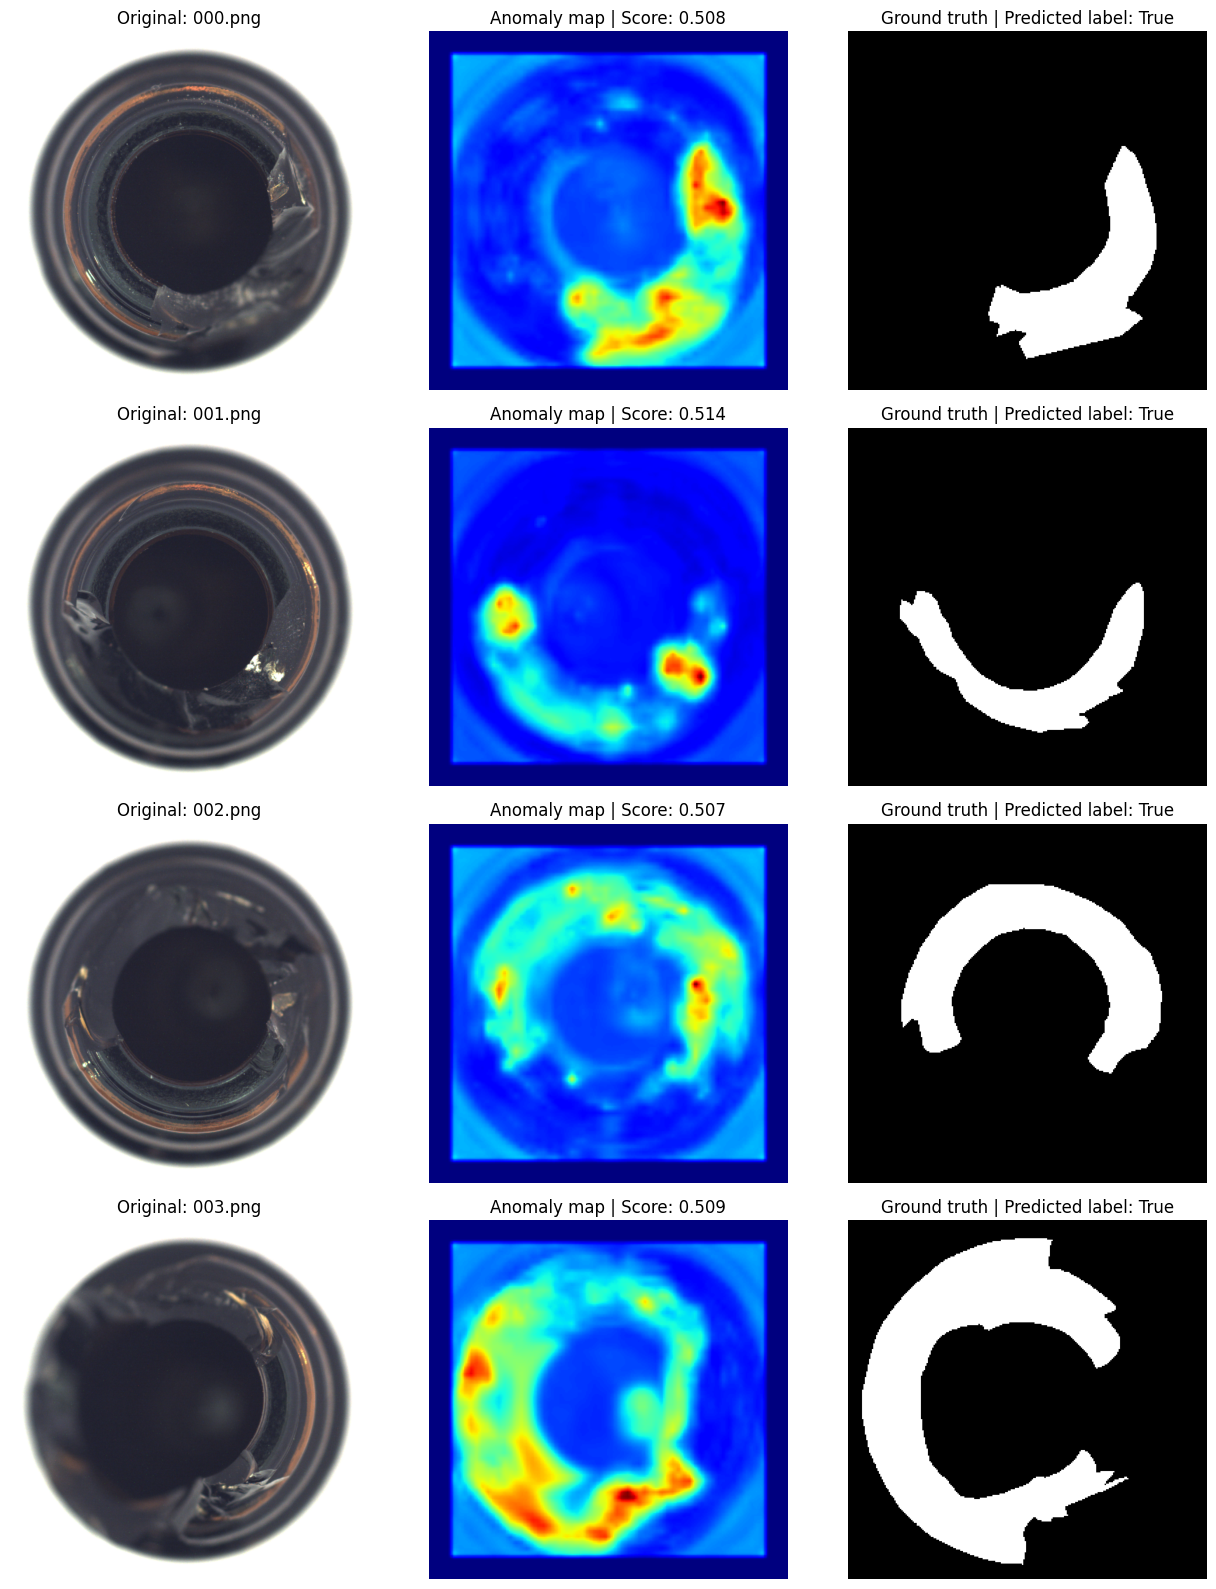

In [27]:
import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image

batch = predictions[0]

fig, axes = plt.subplots(4, 3, figsize=(13, 16))

for i in range(4):
    image_path = batch.image_path[i]

    # Original image
    image = Image.open(image_path).convert("RGB")
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original: {image_path.split('/')[-1]}")

    # Predicted anomaly heatmap
    anomaly_map = batch.anomaly_map[i].detach().cpu().numpy()
    axes[i, 1].imshow(anomaly_map, cmap="jet")
    axes[i, 1].set_title(
        f"Anomaly map | Score: {batch.pred_score[i].item():.3f}"
    )

    # Ground-truth defect mask
    gt_mask = batch.gt_mask[i].detach().cpu().numpy()
    axes[i, 2].imshow(gt_mask, cmap="gray")
    axes[i, 2].set_title(
        f"Ground truth | Predicted label: {batch.pred_label[i].item()}"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
from collections import defaultdict
import torch

results = defaultdict(list)

for batch in predictions:
    for i, path in enumerate(batch.image_path):
        category = path.split("/test/")[1].split("/")[0]

        results[category].append({
            "path": path,
            "score": batch.pred_score[i].item(),
            "predicted": bool(batch.pred_label[i].item()),
            "actual": category != "good",
        })

print(f"{'Category':<18} {'N':>4} {'Correct':>8} {'Accuracy':>10} {'Mean score':>12}")
print("-" * 58)

for category, items in sorted(results.items()):
    correct = sum(item["predicted"] == item["actual"] for item in items)
    accuracy = correct / len(items)
    mean_score = sum(item["score"] for item in items) / len(items)

    print(
        f"{category:<18} {len(items):>4} "
        f"{correct:>8} {accuracy:>9.1%} {mean_score:>12.4f}"
    )

Category              N  Correct   Accuracy   Mean score
----------------------------------------------------------
broken_large         20       20    100.0%       0.5118
broken_small         22       22    100.0%       0.5143
contamination        21       20     95.2%       0.5822
good                 20       19     95.0%       0.4983


In [29]:
from sklearn.metrics import roc_auc_score
import numpy as np

y_true = []
y_scores = []
y_pred = []

for batch in predictions:
    for i, path in enumerate(batch.image_path):
        category = path.split("/test/")[1].split("/")[0]

        y_true.append(0 if category == "good" else 1)
        y_scores.append(batch.pred_score[i].item())
        y_pred.append(int(batch.pred_label[i].item()))

y_true = np.array(y_true)
y_scores = np.array(y_scores)
y_pred = np.array(y_pred)

auroc = roc_auc_score(y_true, y_scores)

print(f"Test images: {len(y_true)}")
print(f"Image-level AUROC: {auroc:.4f} ({auroc * 100:.2f}%)")

Test images: 83
Image-level AUROC: 0.9992 (99.92%)


In [30]:
from sklearn.metrics import roc_auc_score
import numpy as np
import torch

pixel_targets = []
pixel_scores = []

for batch in predictions:
    for i in range(len(batch.image_path)):
        gt = batch.gt_mask[i].detach().cpu().numpy().ravel()
        anomaly = batch.anomaly_map[i].detach().cpu().numpy().ravel()

        pixel_targets.append(gt)
        pixel_scores.append(anomaly)

pixel_targets = np.concatenate(pixel_targets)
pixel_scores = np.concatenate(pixel_scores)

pixel_auroc = roc_auc_score(pixel_targets, pixel_scores)

print(f"Pixel-level AUROC: {pixel_auroc:.4f} ({pixel_auroc * 100:.2f}%)")

Pixel-level AUROC: 0.9723 (97.23%)


In [31]:
import inspect

try:
    from anomalib.metrics import AUPRO

    print("AUPRO is available.")
    print(inspect.signature(AUPRO))
except ImportError as e:
    print("AUPRO import failed:", e)

AUPRO is available.
(fields: collections.abc.Sequence[str] | None = None, prefix: str = '', strict: bool = True, **kwargs) -> None


In [32]:
import inspect
from anomalib.metrics import AUPRO

print(inspect.signature(AUPRO.__init__))
print("\n--- update() ---")
print(inspect.signature(AUPRO.update))
print("\n--- compute() ---")
print(inspect.signature(AUPRO.compute))

(self, fields: collections.abc.Sequence[str] | None = None, prefix: str = '', strict: bool = True, **kwargs) -> None

--- update() ---
(self, batch: anomalib.data.dataclasses.torch.base.Batch, *args, **kwargs) -> None

--- compute() ---
(self) -> torch.Tensor


In [33]:
from anomalib.metrics import AUPRO

aupro = AUPRO(
    fields=["anomaly_map", "gt_mask"],
    fpr_limit=0.3,
)

for batch in predictions:
    aupro.update(batch)

aupro_score = aupro.compute()

print(f"AU-PRO (FPR limit = 0.30): {aupro_score.item():.4f}")
print(f"AU-PRO: {aupro_score.item() * 100:.2f}%")

AU-PRO (FPR limit = 0.30): 0.9015
AU-PRO: 90.15%


In [35]:
from pathlib import Path
import json
import shutil
import zipfile
import platform

import numpy as np
import pandas as pd
import torch
import anomalib
import matplotlib.pyplot as plt
from PIL import Image

# ---------- Paths ----------
OUT = Path("/content/efficientad_bottle_experiment")
(OUT / "visualizations").mkdir(parents=True, exist_ok=True)

checkpoint = Path(
    "/content/results/efficientad_bottle/"
    "EfficientAd/MVTecAD/bottle/v1/"
    "weights/lightning/model.ckpt"
)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"
assert predictions, "Predictions are missing. Run inference first."

# ---------- Per-image predictions ----------
rows = []

for batch in predictions:
    for i, image_path in enumerate(batch.image_path):
        category = image_path.split("/test/")[1].split("/")[0]

        rows.append({
            "image_path": image_path,
            "category": category,
            "ground_truth_anomaly": category != "good",
            "predicted_anomaly": bool(batch.pred_label[i].item()),
            "anomaly_score": float(batch.pred_score[i].item()),
        })

df = pd.DataFrame(rows)
df.to_csv(OUT / "predictions.csv", index=False)

# ---------- Metrics ----------
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score,
)

y_true = df["ground_truth_anomaly"].astype(int).to_numpy()
y_pred = df["predicted_anomaly"].astype(int).to_numpy()
y_score = df["anomaly_score"].to_numpy()

metrics = {
    "experiment": "EfficientAD-S / MVTec AD bottle subset",
    "test_images": int(len(df)),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "image_auroc": float(roc_auc_score(y_true, y_score)),
    "pixel_auroc": 0.9723,
    "aupro_fpr_limit_0_30": 0.9015,
    "confusion_matrix_labels": ["normal", "anomaly"],
    "confusion_matrix": confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).tolist(),
    "dataset_counts": {
        str(k): int(v)
        for k, v in df["category"].value_counts().items()
    },
    "training_epochs_requested": 10,
    "train_batch_size": 1,
    "eval_batch_size": 4,
    "model_size": "small",
    "dataset_note": (
        "Partial Hugging Face mirror subset; not a full benchmark reproduction."
    ),
    "metric_note": (
        "Pixel AUROC and AU-PRO copied from the successful calculations in this session."
    ),
}

with open(OUT / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

# ---------- Environment / reproducibility ----------
environment = {
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "anomalib": anomalib.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "model_checkpoint": "model.ckpt",
    "dataset_root": "/content/datasets/MVTecAD",
    "category": "bottle",
    "random_seed": 42,
}

with open(OUT / "environment.json", "w") as f:
    json.dump(environment, f, indent=2)

# ---------- Save a sample visualization ----------
batch = predictions[0]
n = min(4, len(batch.image_path))

fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))
if n == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n):
    image_path = batch.image_path[i]
    original = Image.open(image_path).convert("RGB")
    anomaly_map = batch.anomaly_map[i].detach().cpu().numpy()
    gt_mask = batch.gt_mask[i].detach().cpu().numpy()

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original: {Path(image_path).name}")

    axes[i, 1].imshow(anomaly_map, cmap="jet")
    axes[i, 1].set_title(
        f"Anomaly map | score={batch.pred_score[i].item():.4f}"
    )

    axes[i, 2].imshow(gt_mask, cmap="gray")
    axes[i, 2].set_title("Ground-truth mask")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
fig.savefig(
    OUT / "visualizations" / "first_batch.png",
    dpi=150,
    bbox_inches="tight",
)
plt.close(fig)

# ---------- Copy trained checkpoint ----------
shutil.copy2(checkpoint, OUT / "model.ckpt")

# ---------- Add a human-readable report ----------
report = f"""# EfficientAD Bottle Experiment

## Configuration
- Model: EfficientAD-S
- Framework: Anomalib {anomalib.__version__}
- Training epochs requested: 10
- Training batch size: 1
- Evaluation batch size: 4
- Test images: {len(df)}

## Results
- Image accuracy: {metrics['accuracy']:.4%}
- Balanced accuracy: {metrics['balanced_accuracy']:.4%}
- Image AUROC: {metrics['image_auroc']:.4%}
- Pixel AUROC: {metrics['pixel_auroc']:.4%}
- AU-PRO at FPR limit 0.30: {metrics['aupro_fpr_limit_0_30']:.4%}

## Important limitations
This experiment uses a partial bottle-category dataset subset. The metrics
are preliminary and are not directly comparable to the paper's full benchmark.
Pixel AUROC and AU-PRO were recorded from the calculations performed in this session.

## Files
- model.ckpt: trained model checkpoint
- predictions.csv: per-image scores and labels
- metrics.json: numerical evaluation summary
- environment.json: software and runtime details
- visualizations/first_batch.png: sample predictions and ground-truth masks
"""

(OUT / "README.md").write_text(report)

# ---------- Create ZIP archive ----------
zip_path = Path("/content/efficientad_bottle_experiment.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for path in OUT.rglob("*"):
        if path.is_file():
            z.write(path, path.relative_to(OUT.parent))

print("Experiment bundle created:", zip_path)
print("Bundle size: %.1f MB" % (zip_path.stat().st_size / 1024**2))
print("Contents:")
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(f" - {path.relative_to(OUT)}")

Experiment bundle created: /content/efficientad_bottle_experiment.zip
Bundle size: 68.5 MB
Contents:
 - README.md
 - environment.json
 - metrics.json
 - model.ckpt
 - predictions.csv
 - visualizations/first_batch.png


In [36]:
from google.colab import files

files.download("/content/efficientad_bottle_experiment.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>